# Adónde va la luz: del patrón de fase del SLM al plano focal

**Pregunta:** ¿En qué lugar del plano focal envía la luz un patrón de fase del modulador espacial de luz, y qué limita el tamaño del campo y la potencia que llega a una trampa?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** ninguno, este es el notebook de entrada del conjunto
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Un arreglo de pinzas ópticas holográficas parte de un hecho: un modulador espacial de luz (SLM) de cristal líquido cambia la fase de un haz láser píxel por píxel, una lente convierte esa fase en un patrón de luz en su plano focal, y cada trampa es un punto brillante de ese patrón. Todos los métodos de los notebooks siguientes solo eligen la fase. Este notebook explica qué hace esa fase, con el motor del producto y un caso real. Al terminar puedes predecir dónde pone su punto una red de difracción blazed, decir qué ancho tiene la ventana útil y qué ocurre fuera de ella, estimar cuánto pierde una trampa por la apertura del píxel y leer adónde va la potencia de un holograma cuando el SLM tiene pocos niveles de fase o una respuesta no lineal.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry, metrics, modes
from pipeline.model.holo.core.device import Device, device_focal_field, pixel_envelope
from pipeline.model.holo.core.traps import OutOfFieldError, Trap, TrapSet

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


## Datos

El notebook solo necesita la configuración óptica de un caso, ninguna muestra medida.

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: parámetros sintéticos escritos por el producto (ningún conjunto de datos de terceros), cubiertos por la licencia del repositorio.
- Archivo leído: `data/examples/cases.json`, caso C01 (láser de 850 nm, distancia focal de 6 mm, 256 por 256 píxeles de 20 um, haz gaussiano).

In [2]:
# case C01 supplies the optical setup; only its setup block is used here
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
setup = setup_of(records["C01_square_grid"])
print("longitud de onda", setup.wavelength_m * 1e9, "nm,", "distancia focal", setup.focal_m * 1e3, "mm")
print("SLM", setup.n_pix, "x", setup.n_pix, "píxeles de", setup.pitch_m * 1e6, "um; FFT", setup.n_fft, "x", setup.n_fft)

longitud de onda 850.0 nm, distancia focal 6.0 mm
SLM 256 x 256 píxeles de 20.0 um; FFT 512 x 512


## Método

Sea un SLM de $N \times N$ píxeles con paso $p$, iluminado por un haz de amplitud $A_j$, y sea $\phi_j$ la fase que muestra. Una lente de distancia focal $f$ colocada a una distancia focal del SLM produce en su plano focal la transformada de Fraunhofer del campo del SLM, de modo que el campo en el punto $(x, y)$ del plano focal es proporcional a $\sum_j A_j e^{i\phi_j} e^{-2\pi i (x x_j + y y_j)/(\lambda f)}$. Una trampa $m$ en $(x_m, y_m)$ recibe la fracción de potencia $I_m = |V_m|^2$ con $V_m = \frac{1}{N^2}\sum_j A_j e^{i(\phi_j - \Delta_j^m)}$ y $\Delta_j^m = \frac{2\pi}{\lambda f}(x_j x_m + y_j y_m)$ para una trampa en el plano focal (Di Leonardo et al. 2007, ecuaciones 1 a 4, https://doi.org/10.1364/OE.15.001913). El motor evalúa esa suma de forma directa y también con una transformada rápida de Fourier con relleno de ceros sobre una grilla de $\mathrm{pad}\,N$ bins. Los cinco pasos siguientes siguen la luz desde el muestreo del plano focal hasta las pérdidas de un dispositivo real.

La transformada muestrea el plano focal, así que lo primero que hay que conocer es la grilla. Un bin de la transformada con relleno mide $\lambda f/(\mathrm{pad}\,N p)$, y la grilla abarca exactamente un período $\lambda f/p$ de las réplicas que crea el muestreo por píxeles, de modo que la semiventana sin solapamiento es $\lambda f/(2p)$ (el bin sigue a Schroff et al. 2023, https://doi.org/10.1038/s41598-023-30296-6; la semiventana se deriva de él en el registro de investigación del producto). La celda imprime esas tres longitudes para el caso C01 y la mayor potencia que puede recibir una trampa sola: con un haz gaussiano recortado por un SLM cuadrado, el campo de una trampa es el promedio de la amplitud $A_j$, de modo que su potencia es a lo sumo $\bar A^2$.

In [3]:
# the sampling of the focal plane: one bin, the half window and the replica period
bin_m = geometry.focal_bin_m(setup)
bin_um = bin_m * 1e6
half_um = geometry.half_field_m(setup) * 1e6
print(f"bin focal {bin_um:.4f} um, semiventana {half_um:.2f} um, período de las réplicas {2 * half_um:.2f} um")
ceiling = geometry.input_amplitude(setup).mean() ** 2
print(f"una trampa sola puede recibir como máximo el cuadrado de la amplitud media del haz, (mean A)^2 = {ceiling:.4f}")

bin focal 0.4980 um, semiventana 127.50 um, período de las réplicas 255.00 um
una trampa sola puede recibir como máximo el cuadrado de la amplitud media del haz, (mean A)^2 = 0.8695


Ahora un holograma. Una rampa lineal de fase, una red de difracción blazed, envía la luz a un solo lugar: $\phi_j = \frac{2\pi}{\lambda f}(x_j x_m + y_j y_m)$ envuelta en $[0, 2\pi)$. La celda siguiente construye esa rampa para un punto situado 40 bins a la derecha del eje, la transforma al plano focal y busca el bin más brillante. Si la luz llega al plano focal en el lugar pedido y con la fracción de potencia que predijo la celda anterior, la geometría del motor es la de las ecuaciones.

In [4]:
# a blazed grating that should send all the light to a trap 40 bins to the right of the axis
centre = setup.n_fft // 2
x_trap = 40 * bin_m
phi = modes.grating_phase(setup, x_trap, 0.0)
field = forward.fft_focal_field(phi, setup)
power = np.abs(field) ** 2 * setup.pad**2 / setup.n_pix**2
iy, ix = np.unravel_index(np.argmax(power), power.shape)
print(f"pico en x = {(ix - centre) * bin_um:.3f} um, y = {(iy - centre) * bin_um:.3f} um")
print(f"pedido x = {x_trap * 1e6:.3f} um")
print(f"potencia en el pico, como fracción de la potencia de entrada: {power[iy, ix]:.4f}")

pico en x = 19.922 um, y = 0.000 um
pedido x = 19.922 um
potencia en el pico, como fracción de la potencia de entrada: 0.8695


El motor tiene dos maneras de leer una trampa. La forma de trampa puntual suma sobre los píxeles del SLM tal como dice la ecuación de la sección Método; la forma FFT lee la grilla transformada en el bin más cercano. Deben coincidir para una trampa que está sobre un bin, porque la segunda forma es la primera evaluada sobre la grilla. La celda compara las dos para la trampa recién construida.

In [5]:
# the same trap read with the point-trap sum and from the FFT grid
traps = TrapSet([Trap(0, x_trap, 0.0)])
v_point = forward.point_trap_fields(phi, setup, traps)
v_fft = forward.trap_fields_from_fft(field, setup, traps)
print("forma de trampa puntual |V|^2:", np.abs(v_point) ** 2, "forma FFT |V|^2:", np.abs(v_fft) ** 2)
print("mayor diferencia de los dos V:", float(np.abs(v_point - v_fft).max()))

forma de trampa puntual |V|^2: [0.86948925] forma FFT |V|^2: [0.86948925]
mayor diferencia de los dos V: 2.699599995149934e-16


La figura siguiente muestra los dos lados de la transformada para esa red: los píxeles centrales del holograma, una sierra de franjas cuyo paso fija el ángulo, y la potencia en el plano focal en escala logarítmica, para que se vea la estructura débil.

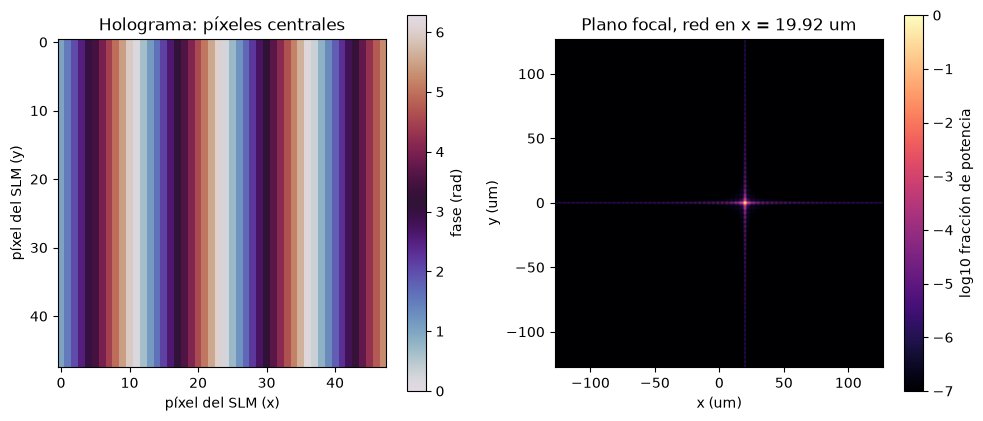

In [6]:
# left: the central 48 x 48 pixels of the hologram; right: the focal power on a log scale
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.3))
c = setup.n_pix // 2
im1 = ax1.imshow(phi[c - 24:c + 24, c - 24:c + 24], cmap="twilight", vmin=0, vmax=2 * np.pi)
ax1.set_title("Holograma: píxeles centrales")
ax1.set_xlabel("píxel del SLM (x)")
ax1.set_ylabel("píxel del SLM (y)")
fig.colorbar(im1, ax=ax1, label="fase (rad)")
ext = [-half_um - bin_um / 2, half_um - bin_um / 2] * 2
im2 = ax2.imshow(np.log10(power + 1e-9), origin="lower", extent=ext, vmin=-7, vmax=0, cmap="magma")
ax2.set_title("Plano focal, red en x = 19.92 um")
ax2.set_xlabel("x (um)")
ax2.set_ylabel("y (um)")
fig.colorbar(im2, ax=ax2, label="log10 fracción de potencia")
fig.tight_layout()
plt.show()

El holograma es un conjunto de franjas rectas; cada franja es una vuelta completa de fase, y casi cuatro caben en los 48 píxeles mostrados, que es el ángulo que lleva el punto a unos 20 um del eje. El plano focal tiene un punto brillante en ese lugar y, en escala logarítmica, una cruz de colas débiles a lo largo de los dos ejes: vienen del borde cuadrado del SLM y del recorte gaussiano, y no son ruido, porque el cálculo no tiene ninguno. La figura no muestra el ancho del punto, que fija la apertura del SLM y es de unos dos bins, ni ninguna imperfección de un SLM real; los pasos siguientes las agregan.

¿Hasta dónde del eje puede estar una trampa? La grilla tiene una ventana finita y la transformada es periódica, de modo que un punto pedido más allá de la semiventana no puede aparecer fuera de ella. La celda pide redes que ponen un punto a 100, 140 y 200 um e imprime dónde está el bin más brillante. Como las réplicas se repiten con período $\lambda f/p$, un punto en $x$ más allá de $\lambda f/(2p)$ aparece en $x - \lambda f/p$, y la celda lo comprueba con el pedido del medio.

In [7]:
# a trap beyond the half window: the FFT form folds it back onto the grid
cuts = {}
for x_um in (100.0, 140.0, 200.0):
    phi_far = modes.grating_phase(setup, x_um * 1e-6, 0.0)
    power_far = np.abs(forward.fft_focal_field(phi_far, setup)) ** 2 * setup.pad**2 / setup.n_pix**2
    cuts[x_um] = power_far[centre]
    seen = (np.argmax(cuts[x_um]) - centre) * bin_um
    print(f"pedido {x_um:6.1f} um -> hallado {seen:8.2f} um")

pedido  100.0 um -> hallado   100.11 um
pedido  140.0 um -> hallado  -115.05 um
pedido  200.0 um -> hallado   -54.79 um


Una trampa fuera de la ventana no es un holograma algo peor: es un pedido que no se puede cumplir, porque la réplica real cae en otro lugar. Por eso la forma de trampa puntual lo rechaza con un mensaje que nombra la trampa y el límite. La celda pide la trampa a 140 um e imprime el rechazo.

In [8]:
# the point-trap form refuses the same trap and says why
try:
    forward.point_trap_fields(phi_far, setup, TrapSet([Trap(0, 140e-6, 0.0)]))
except OutOfFieldError as err:
    print(err)

trap 0 has x = 1.400e-04 m, outside the unaliased field of view (bound = 1.275e-04 m = lambda f / (2 p))


Los cortes de los tres hologramas a lo largo del eje muestran lo mismo de forma gráfica. Las líneas punteadas marcan los bordes de la ventana en más y menos $\lambda f/(2p)$.

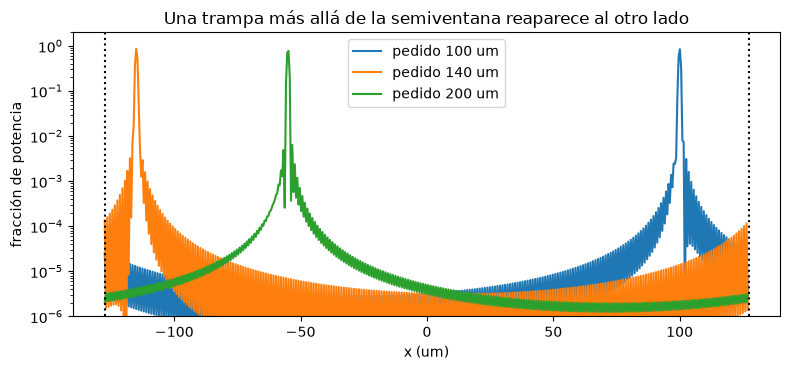

In [9]:
# the cut along y = 0 of the three holograms, on a log scale, with the window edges marked
fig, ax = plt.subplots(figsize=(8, 3.8))
axis = (np.arange(setup.n_fft) - centre) * bin_um
for x_um, cut in cuts.items():
    ax.semilogy(axis, cut + 1e-9, label=f"pedido {x_um:.0f} um")
ax.axvline(-half_um, color="k", ls=":")
ax.axvline(half_um, color="k", ls=":")
ax.set_ylim(1e-6, 2)
ax.set_xlabel("x (um)")
ax.set_ylabel("fracción de potencia")
ax.set_title("Una trampa más allá de la semiventana reaparece al otro lado")
ax.legend()
fig.tight_layout()
plt.show()

El punto pedido a 100 um está dentro de la ventana y aparece donde se pidió. El punto pedido a 140 um aparece en el lugar simétrico cerca de menos 115 um, que es 140 menos el período de 255 um; el pedido a 200 um aparece en torno a menos 55 um por la misma razón. En el dispositivo real la réplica es luz física que viaja con la trampa, de modo que el campo útil es la ventana de ancho $\lambda f/p$ y no más. La figura no dice cuánta potencia llevan las réplicas (eso es la envolvente del píxel de más abajo) ni cómo cambia la ventana con la lente: escala con $f/p$ y con la longitud de onda.

El píxel mismo tiene un tamaño. Un píxel cuadrado de ancho $a = \sqrt{\text{fill}}\,p$ multiplica el campo focal por $\mathrm{sinc}(a x/(\lambda f))\,\mathrm{sinc}(a y/(\lambda f))$, de modo que la potencia de una trampa cae con su distancia al eje (derivado en el registro de investigación del producto y comprobado allí contra una transformada de fuerza bruta). La celda mueve una trampa de red desde el eje hasta el último bin de la ventana, mide la potencia de su pico con la apertura del píxel de un dispositivo con factor de llenado 1 y sin ella, e imprime la razón junto a la fórmula `pixel_envelope`. Ambas deben coincidir, porque la segunda es la forma cerrada de la primera.

In [10]:
# the peak power of a grating trap with and without the pixel aperture, against its position
bins = np.append(np.arange(0, 256, 16), 255)
ratio = []
for k in bins:
    phi_k = modes.grating_phase(setup, k * bin_m, 0.0)
    ideal = np.abs(forward.fft_focal_field(phi_k, setup)[centre, centre + k]) ** 2
    real = np.abs(device_focal_field(phi_k, setup, Device(), None)[centre, centre + k]) ** 2
    ratio.append(real / ideal)
envelope = pixel_envelope(setup, Device())[centre, centre:]
for k, r in list(zip(bins, ratio))[::4]:
    print(f"x = {k * bin_um:6.1f} um  razón medida {r:.4f}  fórmula {envelope[k]:.4f}")
print(f"razón en el último bin, fórmula: {envelope[255]:.4f}")

x =    0.0 um  razón medida 1.0000  fórmula 1.0000
x =   31.9 um  razón medida 0.9496  fórmula 0.9496
x =   63.8 um  razón medida 0.8106  fórmula 0.8106
x =   95.6 um  razón medida 0.6150  fórmula 0.6150
x =  127.0 um  razón medida 0.4085  fórmula 0.4085
razón en el último bin, fórmula: 0.4085


La figura dibuja las razones medidas como puntos sobre la fórmula como línea.

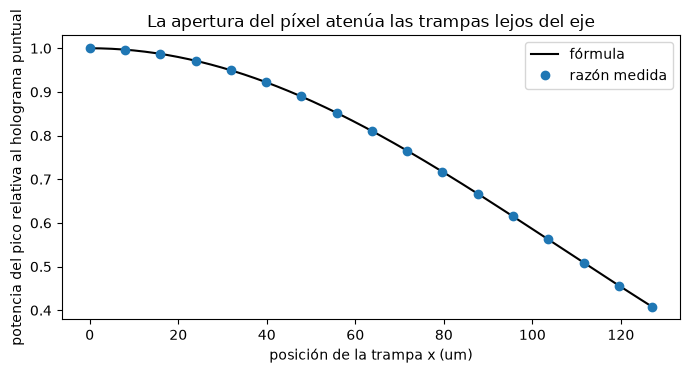

In [11]:
# measured ratio (dots) on the formula sinc^2(sqrt(fill) k / n_fft)^2 (line)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(np.arange(256) * bin_um, envelope, "k-", label="fórmula")
ax.plot(bins * bin_um, ratio, "o", label="razón medida")
ax.set_xlabel("posición de la trampa x (um)")
ax.set_ylabel("potencia del pico relativa al holograma puntual")
ax.set_title("La apertura del píxel atenúa las trampas lejos del eje")
ax.legend()
fig.tight_layout()
plt.show()

Los puntos caen sobre la línea en toda la ventana: una trampa a 64 um del eje conserva cerca de 0,81 de su potencia y una trampa en el último bin conserva cerca de 0,41, pues la intensidad de la fórmula en el borde es $\mathrm{sinc}^2(1/2)$. Es una pérdida del dispositivo, no del algoritmo, y el holograma no puede corregirla salvo que pida más potencia a las trampas exteriores, lo que los notebooks posteriores hacen con pesos. La figura supone un factor de llenado 1 (sin zona muerta entre píxeles) y píxeles cuadrados; un factor de llenado menor que 1 sube la envolvente porque la apertura es menor, pero entonces la zona muerta desperdicia potencia de entrada que este modelo no cuenta.

El otro límite de un SLM real es que su fase tiene pocos niveles. Una escalera de $L = 2^b$ niveles reemplaza la rampa suave, y para una red blazed el primer orden lleva una fracción $\mathrm{sinc}^2(1/L)$ de lo que llevaría la rampa suave (un resultado estándar de la red en escalera, que este notebook comprueba numéricamente en vez de citar). La celda cuantiza la misma red a 1, 2, 3, 4 y 8 bits con el modelo de dispositivo, reparte la potencia con `power_budget` entre la trampa, el orden cero, los fantasmas y lo que queda fuera de la grilla, e imprime la fracción en la trampa junto a la predicción de la escalera escalada a la trampa de 8 bits.

In [12]:
# where the power of the same grating goes when the SLM shows 1 to 8 bits
reference = metrics.power_budget(device_focal_field(phi, setup, Device(bit_depth=8), None), setup, traps)
rows = {}
for bits in (1, 2, 3, 4, 8):
    field_q = device_focal_field(phi, setup, Device(bit_depth=bits), None)
    rows[bits] = metrics.power_budget(field_q, setup, traps)
    theory = np.sinc(1 / 2**bits) ** 2 * reference["traps"]
    got = rows[bits]
    print(f"{bits} bit: en la trampa {got['traps']:.4f} (teoría de la escalera {theory:.4f})")
    print(f"      en los fantasmas {got['ghosts']:.4f}")

1 bit: en la trampa 0.3699 (teoría de la escalera 0.3696)
      en los fantasmas 0.5666
2 bit: en la trampa 0.7399 (teoría de la escalera 0.7393)
      en los fantasmas 0.1966
3 bit: en la trampa 0.8668 (teoría de la escalera 0.8661)
      en los fantasmas 0.0970
4 bit: en la trampa 0.9011 (teoría de la escalera 0.9004)
      en los fantasmas 0.0759
8 bit: en la trampa 0.9121 (teoría de la escalera 0.9120)
      en los fantasmas 0.0676


Las barras apiladas muestran el mismo balance para las cinco profundidades de bits.

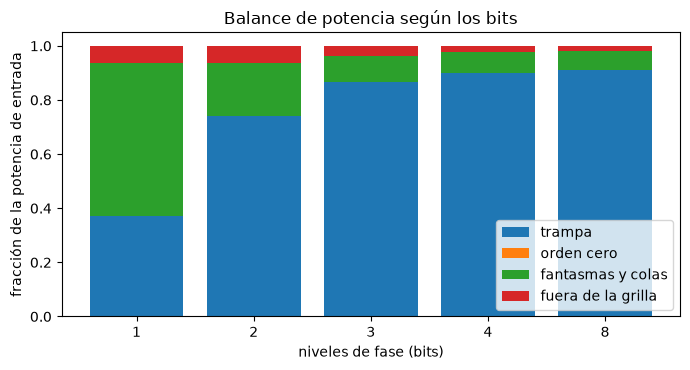

In [13]:
# the power budget as stacked bars, one bar per bit depth
fig, ax = plt.subplots(figsize=(7, 3.8))
labels = {
    "traps": "trampa",
    "zero_order": "orden cero",
    "ghosts": "fantasmas y colas",
    "remainder": "fuera de la grilla",
}
bottom = np.zeros(len(rows))
for part, label in labels.items():
    values = np.array([rows[b][part] for b in rows])
    ax.bar([str(b) for b in rows], values, bottom=bottom, label=label)
    bottom += values
ax.set_xlabel("niveles de fase (bits)")
ax.set_ylabel("fracción de la potencia de entrada")
ax.set_title("Balance de potencia según los bits")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

Con 1 bit la trampa tiene 0,37 de la potencia de entrada y los fantasmas tienen 0,57; con 2 bits la trampa tiene 0,74; desde 4 bits la fracción en la trampa queda a menos de 1,2 por ciento de su valor de 8 bits de 0,91, y las predicciones impresas de la escalera coinciden con las fracciones medidas en menos de 0,001. El resto de 8 bits es la apertura y el recorte gaussiano, no la cuantización. La potencia que queda en los fantasmas no se pierde para el SLM, pero es luz donde nadie la quiere, y en un arreglo de trampas suma un fondo que los pesos de los notebooks posteriores no pueden quitar. La figura supone una respuesta de fase lineal e ideal; la celda siguiente la relaja.

Un píxel real de cristal líquido no responde de forma lineal a su nivel de comando. `lut_gamma` curva la respuesta como $2\pi (\text{nivel}/2\pi)^\gamma$, y un píxel que no da la fase que se le ordenó deja una componente constante en el campo, que es luz en el orden cero, el bin sobre el eje óptico. La celda sube el exponente de 1 a 1,5 e imprime la fracción del pico en el orden cero y la fracción en la trampa.

In [14]:
# a phase response that is not linear in the level leaks light into the zero order
for gamma in (1.0, 1.1, 1.25, 1.5):
    field_g = device_focal_field(phi, setup, Device(lut_gamma=gamma), None)
    zero = metrics.zero_order_fraction(field_g, setup)
    budget = metrics.power_budget(field_g, setup, traps)
    print(f"gamma {gamma:4.2f}: pico del orden cero {zero:.4f}, en la trampa {budget['traps']:.4f}")

gamma 1.00: pico del orden cero 0.0000, en la trampa 0.9121
gamma 1.10: pico del orden cero 0.0016, en la trampa 0.9083
gamma 1.25: pico del orden cero 0.0085, en la trampa 0.8916
gamma 1.50: pico del orden cero 0.0275, en la trampa 0.8458


La fracción del pico en el orden cero es 0,0016 para un exponente de 1,1, 0,0085 para 1,25 y 0,0275 para 1,5, partiendo de un valor cercano a cero para el dispositivo lineal, mientras la trampa pierde potencia de 0,912 a 0,846. El orden cero es un punto brillante más sobre el eje y compite por la misma luz que las trampas cercanas. Los números son los de este modelo de dispositivo; el modelo no tiene una medición detrás de su exponente, de modo que los valores muestran el mecanismo, no un dispositivo.

## Resultados

**Respuesta:** La luz de un patrón de fase llega adonde su transformada de Fourier la pone. Una red blazed que pidió un punto a 19,92 um del eje dio su bin más brillante en 19,922 um con 0,8695 de la potencia de entrada, que es lo máximo que puede recibir una trampa sola con este haz gaussiano. El bin mide 0,498 um y la ventana sin solapamiento es de 127,50 um a cada lado, así que el campo mide 255,00 um de ancho: un punto pedido a 140 um reaparece en menos 115,05 um, y la forma de trampa puntual lo rechaza. Dentro de la ventana la apertura del píxel cuesta potencia con la distancia, hasta 0,41 del pico en el último bin. Los niveles de fase también cuestan potencia: la trampa conserva 0,74 de la entrada con 2 bits y 0,91 desde 4 bits, y una respuesta no lineal pone hasta 0,0275 del pico en el orden cero con un exponente de 1,5. Estos límites son propiedades del SLM y de la lente, de modo que todos los métodos de los notebooks siguientes trabajan dentro de ellos.

## Resumen

El plano focal es la transformada del campo del SLM. Una trampa ocupa un bin de ancho $\lambda f/(\mathrm{pad}\,Np)$, la ventana es $\pm\lambda f/(2p)$, y el muestreo crea réplicas fuera de ella. La apertura del píxel multiplica la intensidad por una envolvente sinc al cuadrado, los niveles finitos de fase mueven potencia a los fantasmas y una respuesta no lineal pone luz sobre el eje. El notebook siguiente convierte estas pérdidas en números para un arreglo de trampas: eficiencia, uniformidad y balance de potencia.

## Referencias

- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- Schroff et al., "Accurate holographic light potentials using pixel crosstalk modelling", Scientific Reports 13 (2023), https://doi.org/10.1038/s41598-023-30296-6.